# T23. Indicadores origen–destino y líneas de deseo

**Qué queremos ver.** Qué zonas concentran viajes, qué flujos conectan zonas distintas y cuánto se desequilibran sus dos sentidos. Usamos las matrices T22 y mantenemos los cortes por franja, tipo de día y periodo.

**Por qué importa.** El volumen de un par describe el intercambio entre zonas. El saldo de los dos sentidos aporta información distinta para la ubicación y el dimensionamiento de estaciones.

## 1. Flujos, concentración y asimetría

**Qué queremos ver.** Cuota intrazonal, volumen de los pares principales y diferencia entre pares recíprocos. Los indicadores espaciales se calculan sobre viajes con ambos extremos asignados y se informa cuántos quedan fuera.

**Por qué importa.** Un par con pocas observaciones puede ser asimétrico por azar. Comparamos la suma de diferencias con la que se esperaría si, fijado el total de cada par, ambos sentidos tuvieran probabilidad 1/2.

In [1]:
import json
from functools import cache

import geopandas as gpd
import h3
import numpy as np
import pandas as pd
from IPython.display import display
from pyproj import Transformer
from scipy.stats import binom
from shapely import get_parts
from shapely.geometry import box

from comun.config import carpeta_tablas, ruta
from comun.figuras import guardar_figura, plt
from comun.web import exportar

TEMA = "movilidad"
TABLAS = carpeta_tablas(TEMA)
CLAVES = ["nivel", "periodo", "tipo_dia", "franja"]
SIN_ZONA = "SIN_ASIGNAR"

temporal = pd.read_csv(TABLAS / "T22_matrices.csv", dtype={"origen": str, "destino": str})
segmentos = pd.read_csv(TABLAS / "T22_segmentos.csv")
meses = segmentos["periodo"].drop_duplicates().tolist()
niveles = temporal["nivel"].drop_duplicates().tolist()
totales = temporal.groupby(["nivel", "periodo", "origen", "destino"], as_index=False)["viajes"].sum()
todos = pd.concat([temporal, totales.assign(tipo_dia="todos", franja="todas")], ignore_index=True)
grupos = {clave: datos for clave, datos in todos.groupby(CLAVES, sort=False)}


@cache
def desequilibrio_esperado(n):
    ida = np.arange(n + 1)
    return float(np.dot(np.abs(2 * ida - n), binom.pmf(ida, n, 0.5)))


def analizar_pares(matriz):
    validos = matriz.loc[matriz["origen"].ne(SIN_ZONA) & matriz["destino"].ne(SIN_ZONA),
                         ["origen", "destino", "viajes"]]
    diagonal = validos["origen"].eq(validos["destino"])
    ida = validos.loc[validos["origen"].lt(validos["destino"])].rename(columns={"viajes": "ida"})
    vuelta = validos.loc[validos["origen"].gt(validos["destino"])].rename(
        columns={"origen": "destino", "destino": "origen", "viajes": "vuelta"}
    )
    pares = ida.merge(vuelta, on=["origen", "destino"], how="outer", validate="one_to_one")
    pares[["ida", "vuelta"]] = pares[["ida", "vuelta"]].fillna(0).astype(int)
    pares["viajes"] = pares["ida"] + pares["vuelta"]
    pares["saldo"] = pares["ida"] - pares["vuelta"]
    pares = pares.sort_values(["viajes", "origen", "destino"], ascending=[False, True, True])
    dentro = int(validos.loc[diagonal, "viajes"].sum())
    entre = int(pares["viajes"].sum())
    n = int(matriz["viajes"].sum())
    assert dentro + entre == int(validos["viajes"].sum())
    esperado = sum(desequilibrio_esperado(v) for v in pares["viajes"])
    diferencia = int(pares["saldo"].abs().sum())
    indicadores = {
        "viajes": n,
        "asignados": dentro + entre,
        "sin_asignar": n - dentro - entre,
        "intrazonales": dentro,
        "pct_intrazonales": 100 * dentro / (dentro + entre) if dentro + entre else np.nan,
        "interzonales": entre,
        "pares_interzonales": len(pares),
        "pct_top10_interzonales": 100 * pares.head(10)["viajes"].sum() / entre if entre else np.nan,
        "asimetria": diferencia / entre if entre else np.nan,
        "asimetria_azar": esperado / entre if entre else np.nan,
        "cociente_asimetria": diferencia / esperado if esperado else np.nan,
    }
    return indicadores, pares


cortes = pd.concat([
    segmentos[CLAVES[1:]], pd.DataFrame({"periodo": meses, "tipo_dia": "todos", "franja": "todas"})
], ignore_index=True)
indicadores, pares_por_corte = [], {}
for nivel in niveles:
    for periodo, tipo, franja in cortes.itertuples(index=False, name=None):
        clave = (nivel, periodo, tipo, franja)
        stats, pares = analizar_pares(grupos.get(clave, temporal[["origen", "destino", "viajes"]].iloc[:0]))
        identificadores = dict(zip(CLAVES, clave))
        indicadores.append(identificadores | stats)
        pares_por_corte[clave] = pares.head(12).assign(**identificadores)

indicadores = pd.DataFrame(indicadores).round(6)
principales = pd.concat(pares_por_corte.values(), ignore_index=True)
indicadores.to_csv(TABLAS / "T23_indicadores.csv", index=False, lineterminator="\n")
principales[[*CLAVES, "origen", "destino", "ida", "vuelta", "viajes", "saldo"]].to_csv(
    TABLAS / "T23_pares_principales.csv", index=False, lineterminator="\n"
)
display(indicadores.loc[indicadores["tipo_dia"].eq("todos")])
display(pares_por_corte["h3", "ajuste", "todos", "todas"].head(5))

,nivel,periodo,tipo_dia,franja,viajes,asignados,sin_asignar,intrazonales,pct_intrazonales,interzonales,pares_interzonales,pct_top10_interzonales,asimetria,asimetria_azar,cociente_asimetria
30,h3,ajuste,todos,todas,16756,16756,0,3588,21.413225,13168,1306,10.639429,0.223117,0.203889,1.094305
31,h3,reservada,todos,todas,6614,6614,0,1371,20.728757,5243,966,9.841694,0.295823,0.300900,0.983128
32,h3,mes,todos,todas,23370,23370,0,4959,21.219512,18411,1478,10.238444,0.204280,0.178152,1.146660
63,municipio,ajuste,todos,todas,16756,16739,17,12342,73.732003,4397,35,88.310212,0.057084,0.048765,1.170601
64,municipio,reservada,todos,todas,6614,6607,7,4842,73.285909,1765,33,89.745042,0.075354,0.077402,0.973548
65,municipio,mes,todos,todas,23370,23346,24,17184,73.605757,6162,38,88.721194,0.052580,0.041520,1.266393
96,zona_urbanistica,ajuste,todos,todas,16756,16739,17,7060,42.176952,9679,430,25.322864,0.148879,0.125340,1.187797
97,zona_urbanistica,reservada,todos,todas,6614,6607,7,2709,41.001968,3898,363,24.345818,0.180605,0.196666,0.918335
98,zona_urbanistica,mes,todos,todas,23370,23346,24,9769,41.844427,13577,484,24.917139,0.138690,0.109477,1.266842


,origen,destino,ida,vuelta,viajes,saldo,nivel,periodo,tipo_dia,franja
620,881e805089fffff,881e8050c1fffff,105,74,179,31,h3,ajuste,todos,todas
706,881e8050c3fffff,881e8050c7fffff,88,86,174,2,h3,ajuste,todos,todas
621,881e805089fffff,881e8050c3fffff,73,91,164,-18,h3,ajuste,todos,todas
21,881e805003fffff,881e80501dfffff,85,74,159,11,h3,ajuste,todos,todas
627,881e805089fffff,881e8050d5fffff,77,58,135,19,h3,ajuste,todos,todas


**Conclusiones.** El saldo se lee como viajes de origen a destino menos los del sentido inverso. La asimetría es la suma de los valores absolutos del saldo dividida por el volumen interzonal, contando cada par una vez. El cociente frente al azar es descriptivo y ayuda a interpretar los cortes con recuentos pequeños.

## 2. Mapa de líneas de deseo H3

**Qué queremos ver.** Dónde están los doce pares de celdas con más intercambio en el ajuste. Cada línea une los centros de las celdas. El grosor expresa el total de los dos sentidos y la flecha señala el sentido predominante.

**Por qué importa.** Localiza los pares de mayor demanda sin confundir las conexiones agregadas con las trayectorias de los patinetes. La vista web compara los tres periodos con el mismo encuadre y la misma escala de grosor.

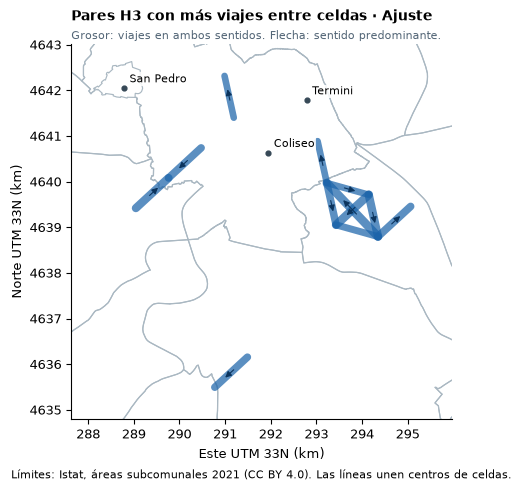

In [2]:
ficha = ruta("externos") / "istat" / "istat_asc_2021_2026-11-21.meta.json"
meta = json.loads(ficha.read_text(encoding="utf-8"))
archivo = ficha.with_name(meta["fichero"])
capa = meta["capas"]["municipio"]
barrios = gpd.read_file(f"zip://{archivo.as_posix()}!{capa}", where=meta["filtro"]).to_crs("EPSG:32633")
proyectar = Transformer.from_crs("EPSG:4326", barrios.crs, always_xy=True).transform
referencias = {
    "Termini": (12.5019, 41.9009),
    "Coliseo": (12.4922, 41.8903),
    "San Pedro": (12.4536, 41.9022),
}

periodos_web = {}
for periodo in meses:
    top = pares_por_corte["h3", periodo, "todos", "todas"][["origen", "destino", "ida", "vuelta", "viajes", "saldo"]]
    periodos_web[periodo] = {
        "pares": top,
        "resumen": indicadores.loc[
            indicadores["nivel"].eq("h3") & indicadores["periodo"].eq(periodo) & indicadores["tipo_dia"].eq("todos")
        ].iloc[0].to_dict(),
    }

celdas = sorted({
    celda
    for corte in periodos_web.values()
    for lado in ("origen", "destino")
    for celda in corte["pares"][lado]
})
centros = {celda: proyectar(*reversed(h3.cell_to_latlng(celda))) for celda in celdas}
lugares = {nombre: proyectar(*punto) for nombre, punto in referencias.items()}
x, y = np.asarray([*centros.values(), *lugares.values()]).T
margen = 700
limites = (x.min() - margen, y.min() - margen, x.max() + margen, y.max() + margen)
bordes = barrios.boundary.intersection(box(*limites))
lineas = [
    np.asarray(parte.coords) / 1000
    for borde in bordes
    for parte in get_parts(borde)
    if parte.geom_type == "LineString" and not parte.is_empty
]
max_viajes = max((int(corte["pares"]["viajes"].max()) for corte in periodos_web.values()
                 if len(corte["pares"])), default=1)

fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
for linea in lineas:
    ax.plot(*linea.T, color="#aab8c2", linewidth=0.85, zorder=1)
top = periodos_web["ajuste"]["pares"]
for par in top.iloc[::-1].itertuples():
    puntos = np.asarray([centros[par.origen], centros[par.destino]]) / 1000
    ancho = 1 + 6 * np.sqrt(par.viajes / max_viajes)
    ax.plot(*puntos.T, color="#1c64aa", alpha=0.72, linewidth=ancho, solid_capstyle="round", zorder=2)
    if par.saldo:
        a, b = puntos if par.saldo > 0 else puntos[::-1]
        ax.annotate("", xy=a + 0.68 * (b - a), xytext=a + 0.42 * (b - a), zorder=3,
                    arrowprops={"arrowstyle": "-|>", "color": "#0c345d", "lw": 0.8, "shrinkA": 0, "shrinkB": 0})

for nombre, punto in lugares.items():
    px, py = np.asarray(punto) / 1000
    ax.scatter(px, py, s=12, color="#374957", zorder=4)
    ax.annotate(nombre, (px, py), xytext=(4, 4), textcoords="offset points", fontsize=8, zorder=4,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 0.8})
ax.set(xlim=(limites[0] / 1000, limites[2] / 1000), ylim=(limites[1] / 1000, limites[3] / 1000),
       xlabel="Este UTM 33N (km)", ylabel="Norte UTM 33N (km)", aspect="equal")
ax.ticklabel_format(style="plain", useOffset=False)
ax.grid(False)
ax.set_title("Pares H3 con más viajes entre celdas · Ajuste", loc="left", fontweight="bold", pad=17)
ax.text(0, 1.013, "Grosor: viajes en ambos sentidos. Flecha: sentido predominante.",
        transform=ax.transAxes, fontsize=8, color="#526576")
fig.supxlabel("Límites: Istat, áreas subcomunales 2021 (CC BY 4.0). Las líneas unen centros de celdas.", fontsize=8)
guardar_figura(fig, TEMA, "T23_lineas_deseo")

exportar("fase1", "t23_lineas_deseo", {
    "periodos": periodos_web,
    "centros": {celda: np.asarray(punto) / 1000 for celda, punto in centros.items()},
    "referencias": {nombre: np.asarray(punto) / 1000 for nombre, punto in lugares.items()},
    "limites": np.asarray(limites) / 1000,
    "bordes": lineas,
    "max_viajes": max_viajes,
})

**Conclusiones.** El mapa ubica las conexiones con más intercambios entre celdas distintas. Las cifras de ida, vuelta y saldo de cada par quedan en la tabla. El mapa usa líneas rectas entre centros de celda como representación de los flujos agregados.